# Can a policy that reads only the context choose options that beat EI? One-deviation option policy from exact labels

## Description

<!-- Written 2026-11-12 before the first run (pre-registration). Reasoning: research_log/decisions/0008 §4 step 3, and the discussion with Tim of 2026-11-12 after option_headroom (notebook 12). Issue #13. -->

**Question.** Notebook 12 found a luck-corrected advantage over EI in "follow arm a for k steps, then EI" (H₃ = 0.195 log10), about half of it context-dependent. That headroom is privileged: the option was chosen with knowledge of the task. **Can a policy that reads only what is known at decision time (the data and the frozen PFN's belief) choose when to deviate and to which option, and beat EI by more than a context-free schedule does?**

Tim's framing (2026-11-12): the aim is to *discover a non-static acquisition rule that decides from the context*. A better static arm (MES, UCB) beats EI under log regret anyway, and would hide whether the algorithm works. So:
- the base policy stays **EI**;
- **MES is not among the options of the primary policy**, so "switch to MES" cannot be the answer;
- the claim that counts is the gain over the **best context-free schedule** from the same options, not the gain over EI alone.

**Setup** (`experimental/option_policy.py`, `tasks/option_policy.py`, `analysis/option_policy.py`). d = 2, n_init = 4, T = 20, pfn_large, fp32, noise-free prior tasks.
- *Deterministic arms*, as in notebook 12: each arm maximizes its acquisition over the seed-s candidate set (1024 scrambled Sobol points plus 64 fixed perturbations of the incumbent at each of σ = 0.01, 0.05, 0.2). Seeds s ∈ {0, 1} are the luck replicates.
- *Tasks.* 2000 fresh prior draws: split 4, task offset 30000 (label tasks; notebook 12 used 20000–20799). Nothing touches split 1.
- *Prefix.* EI under seed 0 for the whole run.
- *Decision steps.* t ∈ {0, 2, …, 14}. At each, from the prefix's data, under both seeds:
  - the **base**: EI to T;
  - the **options**: each of PI(0.01), UCB(0.995), MES, mean for 3 steps and then EI to T, or for the rest of the run. 8 options.
- *Reward.* Terminal log10 regret, log10(best − f\* + ε), ε = 1e-6. The advantage of an option under seed s is log10 R_T(base, s) − log10 R_T(option, s); positive = better. Each is an exact outcome (deterministic policies, noise-free tasks).
  - Under seed 0 the base from every step is the prefix itself, so the advantage is the exact gain over the EI run.
- *Context*, computed at every (task, t) from the prefix's data only:
  - `data` (18 features): budget, the y values' level and gaps, the improvement history, the geometry around the incumbent;
  - `belief` (data + 45): the PFN's predictive on the seed-0 candidate set (max EI, max PI, uncertainty near and far, MES's f\* samples), and for the pick of each of EI, PI, UCB, MES, mean: its distance to the incumbent and to EI's pick, its predicted mean, sd, PI and EI;
  - `pfn` (belief + 32): the first 32 principal components of the PFN's pooled last-layer context states;
  - `time` (t only): a learned schedule that cannot see the context.
- *Value model.* Q(state, option): an MLP (2 × 128, ensemble of 2) regressed by squared error on the advantage averaged over both seeds. A ridge on `belief` as the linear reference.
- *Policy (one deviation).* Follow EI. At the first decision step where max over the portfolio's options of Q exceeds c, commit to that option; afterwards EI to T, no second deviation.
  - Every state the policy decides at is an EI state, so the labels are its exact value: nothing compounds and no off-policy correction is needed.
  - **Conservative acceptance:** c is chosen to maximize the value on training tasks, from predictions those tasks' models never saw. c = ∞ (never deviate = EI) is in the grid and wins ties.
- *Cross-fitting over tasks.* 5 folds. Each task's decision comes from a model and a threshold fitted on the other four folds (thresholds from 4 inner folds inside them). The policy's value on a task is the label of its decision. All 2000 tasks are held-out test tasks once.
- *Portfolios.* `nomes` (**primary**): PI, UCB, mean. `all`: plus MES.
- *Comparators*, all on the same held-out tasks:
  - **EI**: 0 by definition;
  - **static schedule**: the single best (step, option) on the training folds, applied to every held-out task. "Always UCB from step 0" is one of them;
  - **shuffled null**: the policy's own decisions reassigned across held-out tasks. Same deviation rate, steps and options, unrelated to the task's context;
  - **`time` policy**: the same learner without context;
  - **oracle** (privileged): per task the best decision on one seed, scored on the other. The headroom of the one-deviation class.

**What to look for.**
1. **Primary:** `nomes/belief/mlp` under seed 0 (the deployed, deterministic policy; exact closed-loop gain):
   - gain over EI, paired over tasks, bootstrap CI;
   - **gain over the static schedule** = the context-dependent part;
   - gain over its shuffled null.
2. Secondary:
   - the same under seed 1 (option executed on a different candidate set: a luck replicate of the decision);
   - `all` portfolio: does the policy use MES, and does the context still add to it?
   - feature sets: `time` < `data` < `belief` < `pfn`? `belief` vs `data` is the PFN-reading vs D-only comparison;
   - share of the oracle headroom captured;
   - which steps and options the policy chooses, and its deviation rate;
   - held-out fit of Q per option against the label's cross-seed correlation (its noise ceiling);
   - robustness at ε = 1e-5, from the stored raw regrets.

**GO / NO-GO** (rule `analysis/option_policy.py::policy_verdict`, on `nomes/belief/mlp`, seed 0; worthwhile = 0.022 log10, i.e. 5% less regret).
- **GO**: the gain over EI has CI > 0, and the gain over the static schedule has CI > 0 and is ≥ 0.022. A context-reading policy beats EI beyond what a context-free schedule gives. Next: confirm with a frozen policy in closed loop on split 1; allow repeated decisions; d = 4.
- **NO-GO**: the upper CI bound of the gain over the static schedule is < 0.022. The context, as read here, does not identify the option. Next: d = 4, where the headroom should be basin discovery; or richer state readouts.
- **INCONCLUSIVE**: otherwise.

A gain over EI without a gain over the static schedule is *not* a GO: it is "a better default rule than EI", which notebook 12 already showed.

**Limits.**
- Noise-free P0, d = 2, T = 20; at d = 2 the gain is mostly polishing efficiency (notebook 12).
- One deviation per run, at even steps only. Repeated decisions would need labels at the states the new policy visits (the next iteration).
- Q compares "deviate now" with "never deviate", not with "deviate later"; the threshold absorbs part of that.
- The value is exact for seed 0, but offline: read from labels, not from a separate closed-loop run. The confirm stage runs the frozen policy in closed loop.
- Pilot on label tasks (split 4), cross-fitted. Design choices (features, learner, c grid) were fixed before the first run; the 32 PCA directions are fitted on all states' PFN states (no labels involved).
- Two seeds: training targets average them, a coarse luck reduction.


### Note after the sanity run (2026-11-12, before the pilot)

Sanity: `results/option_policy/sanity_20261112-123006`, 100 tasks, 6 min. The pipeline works. No change to the design or the rule.

One addition to what is reported: under seed 0 the base lane from every decision step should reproduce the prefix exactly. It does so only up to GPU floating-point effects: raw regrets differ by at most 7e-6, which is more than 0.01 log10 in 27% of tasks, since near-ties late in a run flip with the batch composition. The labels are therefore exact up to this mean-zero numerical noise, at the scale of ε. The spread of the base lanes across steps is reported as that noise scale.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.option_policy import policy_verdict
from anytime_acq.analysis.stats import bootstrap_ci

SNAPSHOT = "results/option_policy/pilot_20261112-123724"
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached pilot experiment=option_policy task.d=2
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261112-123724` |
| commit | `c36d0c36fbd5` (tag `sweep/option_policy/pilot_20261112-123724`) |
| backend / host | detached / ulysses |
| ran | 2026-11-12T12:37:26 → 2026-11-12T14:39:14 |
| members | 1: 1 done |
| compute | 2.0 h wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/option_policy.yaml`):

```yaml
# @package _global_
# Can a policy that reads only the context choose options that beat EI? One-deviation option policy from exact
# labels (issue #13, decision 0008 §4 step 3). Pre-registration: notebooks/13_2026-11-12_option_policy.ipynb.
defaults:
  - override /task: option_policy

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  arms: '["ei", "pi0.01", "ucb0.995", "mes", "mean"]'
  base: ei
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  device: cuda
  eps: 1.0e-06
  feature_sets: '["time", "data", "belief", "pfn"]'
  fit.batch: 1024
  fit.dropout: 0.1
  fit.epochs: 150
  fit.lr: 0.002
  fit.n_ens: 2
  fit.patience: 15
  fit.weight_decay: 0.001
  fit.width: 128
  ks: '[3]'
  n_boot: 2000
  n_folds: 5
  n_init_per_d: 2
  n_inner: 4
  name: option_policy
  pfn: pfn_large
  portfolios.all: '["pi0.01", "ucb0.995", "mes", "mean"]'
  portfolios.nomes: '["pi0.01", "ucb0.995", "mean"]'
  primary: nomes/belief/mlp
  rest: true
  seeds: '[0, 1]'
  steps: '[0, 2, 4, 6, 8, 10, 12, 14]'
  task_chunk: 500
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  tasks.n_tasks: 2000
  tasks.split: 4
  tasks.task_offset: 30000
  tf32: false
  worthwhile_log10: 0.022
  z_pca: 32
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
print("minutes:", {k: round(float(runs.iloc[0][k]) / 60, 1) for k in runs.columns if k.startswith("time/")})
summ, per, usage, fit, opts = (snap.table(k) for k in ("summary", "per_task", "usage", "fit", "options"))
PRIMARY, WORTH = "nomes/belief/mlp", 0.022
print("held-out tasks:", len(per), "| folds:", per.fold.nunique())

member status: {'DONE': 1}
minutes: {'time/collect_s': 121.2, 'time/evaluate_s': 0.6}
held-out tasks: 2000 | folds: 5


## 1. The primary policy: gain over EI, over the static schedule, over its shuffled null

In [ ]:
def show(variants, seed=0):
    s = summ[summ.variant.isin(variants) & (summ.seed == seed)]
    t = s.assign(ci=[f"{m:+.3f} [{lo:+.3f}, {hi:+.3f}]" for m, lo, hi in zip(s["mean"], s.lo, s.hi)])
    out = t.pivot(index="variant", columns="contrast", values="ci").reindex(variants)
    out["deviates"] = s.groupby("variant").deviates.first().reindex(variants).round(2)
    return out[[c for c in ("vs_base", "vs_static", "vs_shuffled", "deviates") if c in out]]

print("log10 terminal regret, positive = better; paired over held-out tasks, 95% bootstrap CI")
print("seed 0 (the deployed policy; exact gain over the EI run):")
display(show([PRIMARY, "nomes/static"], 0))
print("seed 1 (the decision executed on a different candidate set):")
display(show([PRIMARY, "nomes/static"], 1))
o = summ[summ.variant == "nomes/oracle"].iloc[0]
g = summ[(summ.variant == PRIMARY) & (summ.seed == 0) & (summ.contrast == "vs_base")].iloc[0]
print(f"privileged one-deviation headroom (cross-fitted over seeds): {o['mean']:.3f} [{o.lo:.3f}, {o.hi:.3f}];"
      f" share captured by the policy: {g['mean'] / o['mean']:.0%}")

log10 terminal regret, positive = better; paired over held-out tasks, 95% bootstrap CI
seed 0 (the deployed policy; exact gain over the EI run):


contrast,vs_base,vs_static,vs_shuffled,deviates
variant,,,,
nomes/belief/mlp,"+0.135 [+0.096, +0.174]","+0.017 [-0.018, +0.050]","+0.043 [+0.020, +0.066]",0.87
nomes/static,"+0.119 [+0.074, +0.165]",NaN,NaN,NaN


seed 1 (the decision executed on a different candidate set):


contrast,vs_base,vs_static,vs_shuffled,deviates
variant,,,,
nomes/belief/mlp,"+0.128 [+0.089, +0.166]","+0.026 [-0.022, +0.069]","+0.055 [+0.025, +0.081]",0.87
nomes/static,"+0.102 [+0.057, +0.147]",NaN,NaN,NaN


privileged one-deviation headroom (cross-fitted over seeds): 0.346 [0.308, 0.386]; share captured by the policy: 39%


## 2. Feature sets, learners and portfolios

contrast,vs_base,vs_static,vs_shuffled,deviates
variant,,,,
nomes/time/mlp,"+0.127 [+0.085, +0.170]","+0.009 [-0.026, +0.043]","+0.000 [+0.000, +0.000]",1.00
nomes/data/mlp,"+0.108 [+0.069, +0.148]","-0.011 [-0.045, +0.023]","+0.013 [-0.010, +0.037]",0.90
nomes/belief/mlp,"+0.135 [+0.096, +0.174]","+0.017 [-0.018, +0.050]","+0.043 [+0.020, +0.066]",0.87
nomes/pfn/mlp,"+0.127 [+0.088, +0.167]","+0.009 [-0.028, +0.044]","+0.041 [+0.015, +0.065]",0.91
nomes/belief/ridge,"+0.134 [+0.097, +0.171]","+0.016 [-0.021, +0.050]","+0.049 [+0.023, +0.073]",0.88
nomes/static,"+0.119 [+0.074, +0.165]",NaN,NaN,NaN
all/time/mlp,"+0.123 [+0.084, +0.165]","-0.019 [-0.055, +0.019]","+0.000 [+0.000, +0.000]",0.80
all/data/mlp,"+0.164 [+0.117, +0.210]","+0.023 [-0.009, +0.054]","+0.021 [+0.003, +0.041]",0.99
all/belief/mlp,"+0.168 [+0.125, +0.213]","+0.027 [-0.006, +0.060]","+0.031 [+0.007, +0.054]",0.98


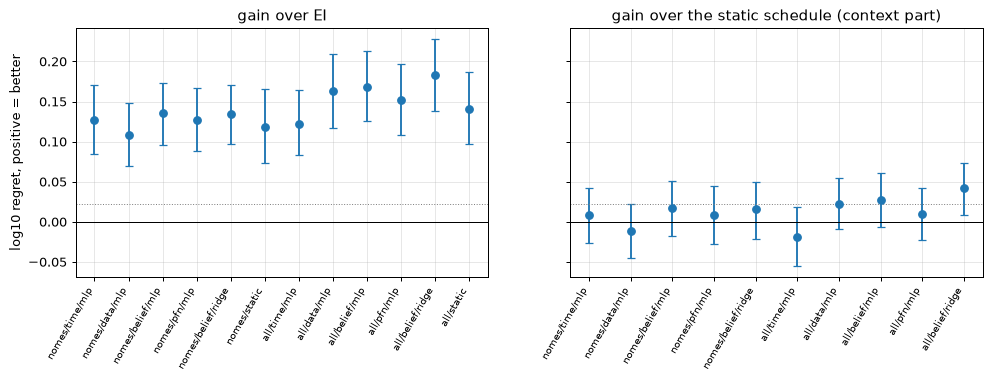

In [ ]:
order = [f"{pf}/{fs}/mlp" for pf in ("nomes", "all") for fs in ("time", "data", "belief", "pfn")]
order = order[:4] + ["nomes/belief/ridge", "nomes/static"] + order[4:] + ["all/belief/ridge", "all/static"]
display(show(order, 0))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), dpi=90, sharey=True)
for a, contrast in zip(ax, ("vs_base", "vs_static")):
    s = summ[(summ.seed == 0) & (summ.contrast == contrast) & summ.variant.isin(order)].set_index("variant").reindex(order).dropna(subset=["mean"])
    a.errorbar(range(len(s)), s["mean"], yerr=[s["mean"] - s.lo, s.hi - s["mean"]], fmt="o", capsize=3)
    a.axhline(0, color="k", lw=.8); a.axhline(WORTH, color="gray", ls=":", lw=.8)
    a.set_xticks(range(len(s))); a.set_xticklabels(s.index, rotation=60, ha="right", fontsize=8)
    a.set_title({"vs_base": "gain over EI", "vs_static": "gain over the static schedule (context part)"}[contrast]); a.grid(alpha=.3)
ax[0].set_ylabel("log10 regret, positive = better"); plt.show()

## 3. What the policy does: steps, options, thresholds

In [ ]:
u = usage[usage.variant.isin([PRIMARY, "all/belief/mlp"])]
for v, g in u.groupby("variant"):
    print(v, "(tasks per decision; step -1 = never deviates)")
    display(g.pivot_table(index="option", columns="step", values="n", aggfunc="sum", fill_value=0))
print("static schedule chosen per fold:"); display(usage[usage.variant.str.endswith("/static")][["variant", "fold", "step", "option"]])
print("thresholds c per fold (primary):", sorted(per.groupby("fold")[f"{PRIMARY}:c"].first().round(3).tolist()))
print("mean advantage per decision step and option (seed 0):")
display(opts.pivot(index="option", columns="step", values="adv0").round(3))

all/belief/mlp (tasks per decision; step -1 = never deviates)


step,-1,0,2,4,6,8,10,12,14
option,,,,,,,,,
base,38,0,0,0,0,0,0,0,0
mean_k3,0,3,0,0,0,0,0,0,0
mes_k3,0,51,5,2,3,4,1,1,3
mes_rest,0,1223,73,32,13,12,1,0,1
pi0.01_k3,0,1,7,9,4,16,8,4,2
pi0.01_rest,0,0,0,0,3,1,1,5,5
ucb0.995_k3,0,31,11,7,4,3,7,0,4
ucb0.995_rest,0,357,28,8,4,2,2,0,0


nomes/belief/mlp (tasks per decision; step -1 = never deviates)


step,-1,0,2,4,6,8,10,12,14
option,,,,,,,,,
base,263,0,0,0,0,0,0,0,0
mean_k3,0,0,1,0,0,1,1,0,1
mean_rest,0,0,0,0,0,0,0,1,2
pi0.01_k3,0,0,6,29,34,41,22,13,17
pi0.01_rest,0,0,0,2,6,1,3,8,6
ucb0.995_k3,0,10,17,12,11,23,23,18,15
ucb0.995_rest,0,872,293,144,61,31,12,0,0


static schedule chosen per fold:


,variant,fold,step,option
0,nomes/static,0,1,ucb0.995_rest
1,nomes/static,1,2,ucb0.995_rest
2,nomes/static,2,1,ucb0.995_rest
3,nomes/static,3,1,ucb0.995_rest
4,nomes/static,4,1,ucb0.995_rest
5,all/static,0,1,mes_rest
6,all/static,1,1,mes_rest
7,all/static,2,0,mes_rest
8,all/static,3,1,mes_rest
9,all/static,4,1,mes_rest


thresholds c per fold (primary): [0.102, 0.111, 0.147, 0.158, 0.172]
mean advantage per decision step and option (seed 0):


step,0,2,4,6,8,10,12,14
option,,,,,,,,
mean_k3,-0.039,-0.054,-0.078,-0.054,-0.024,-0.012,0.009,0.021
mean_rest,-0.930,-0.739,-0.484,-0.303,-0.174,-0.110,-0.048,-0.014
mes_k3,0.071,0.039,0.073,0.084,0.086,0.104,0.101,0.079
mes_rest,0.163,0.156,0.137,0.123,0.102,0.076,0.057,0.038
pi0.01_k3,0.015,0.051,0.084,0.089,0.107,0.118,0.112,0.088
pi0.01_rest,-0.497,-0.457,-0.355,-0.257,-0.159,-0.100,-0.045,-0.024
ucb0.995_k3,0.041,0.065,0.092,0.101,0.096,0.101,0.103,0.100
ucb0.995_rest,0.121,0.131,0.113,0.087,0.062,0.046,0.029,0.023


## 4. How well Q is fitted, against the labels' noise ceiling

In [ ]:
f = fit.pivot_table(index="option", columns=["features", "learner"], values="spearman").round(3)
f["label seed corr"] = fit.groupby("option").seed_corr.first().round(3)
print("held-out Spearman of Q with the seed-mean advantage, per option; last column: correlation of the label across the two seeds")
display(f)
display(fit.groupby(["features", "learner"])[["spearman", "r2"]].mean().round(3))

held-out Spearman of Q with the seed-mean advantage, per option; last column: correlation of the label across the two seeds


features      belief          data    pfn   time label seed corr
learner          mlp  ridge    mlp    mlp    mlp                
option                                                          
mean_k3        0.137  0.125  0.125  0.133  0.057           0.412
mean_rest      0.370  0.367  0.334  0.363  0.284           0.779
mes_k3         0.051  0.055  0.030  0.052  0.015           0.463
mes_rest       0.131  0.127  0.087  0.125  0.042           0.574
pi0.01_k3      0.049  0.049  0.022  0.048  0.030           0.482
pi0.01_rest    0.276  0.274  0.268  0.281  0.176           0.685
ucb0.995_k3    0.033  0.043  0.030  0.040  0.018           0.488
ucb0.995_rest  0.142  0.157  0.110  0.140  0.045           0.631

spearman     r2
features learner                 
belief   mlp         0.148  0.037
         ridge       0.149  0.037
data     mlp         0.126  0.028
pfn      mlp         0.148  0.035
time     mlp         0.083  0.017

## 5. Robustness: ε = 1e-5, and the numerical noise of the labels

In [ ]:
def gain_eps(v, eps, s=0):
    return np.log10(per[f"{v}:regret_base{s}"] + eps) - np.log10(per[f"{v}:regret{s}"] + eps)

rows = []
for v in (PRIMARY, "all/belief/mlp", "nomes/pfn/mlp", "nomes/data/mlp"):
    for eps in (1e-6, 1e-5):
        x = gain_eps(v, eps).to_numpy()
        lo, hi = bootstrap_ci(x, n_boot=2000)
        rows.append({"variant": v, "eps": eps, "gain over EI": x.mean(), "lo": lo, "hi": hi})
print("the same decisions, scored at another eps (the policy itself was trained at eps = 1e-6):")
display(pd.DataFrame(rows).round(3))

the same decisions, scored at another eps (the policy itself was trained at eps = 1e-6):


,variant,eps,gain over EI,lo,hi
0,nomes/belief/mlp,0.0,0.135,0.096,0.174
1,nomes/belief/mlp,0.0,0.105,0.074,0.136
2,all/belief/mlp,0.0,0.168,0.125,0.213
3,all/belief/mlp,0.0,0.133,0.098,0.168
4,nomes/pfn/mlp,0.0,0.127,0.088,0.167
5,nomes/pfn/mlp,0.0,0.099,0.069,0.130
6,nomes/data/mlp,0.0,0.108,0.069,0.148
7,nomes/data/mlp,0.0,0.087,0.056,0.120


## Observations (pilot, snapshot `results/option_policy/pilot_20261112-123724`)

Written after the run. 2000 held-out tasks (5 outer folds), log10 terminal regret, positive = better, ε = 1e-6, seed 0 unless noted. Collection took 121 min, the evaluation 0.6 min.

- **The policy beats EI, but not the best context-free schedule. Verdict by the pre-registered rule: INCONCLUSIVE.**
  - Primary `nomes/belief/mlp`: over EI **+0.135 [0.096, 0.174]** (about 27% less regret); seed 1: +0.128 [0.089, 0.166].
  - The static schedule alone gives +0.119 [0.074, 0.165]. In every fold it is "UCB(0.995) for the rest of the run" from decision index 1 or 2 (t = 2 or 4; the `step` column of the static rows is the index, not t).
  - Policy over static: **+0.017 [−0.018, 0.050]**; seed 1: +0.026 [−0.022, 0.069]. The CI includes 0, and its upper bound is above the worthwhile 0.022, so neither GO nor NO-GO.
- **The context is used, a little.** Over its own shuffled null the policy gains +0.043 [0.020, 0.066] (seed 1: +0.055 [0.025, 0.081]); `time` only: 0 by construction; `data`: +0.013 [−0.010, 0.037].
  - So the belief features carry information that the data features alone do not show, about 0.04 log10.
  - But the policy spends it on making a spread of decisions as good as the one best schedule. It deviates in 87% of tasks, 44% of all tasks at t = 0 to UCB for the rest.
- **Feature sets and learners agree.** `pfn` (belief + 32 PCA components of the PFN state): +0.009 [−0.028, 0.044] over static; ridge on `belief`: +0.016 [−0.021, 0.050]. No learner or feature set separates from static in the primary portfolio. The PFN state adds nothing over the hand-made belief features.
- **With MES among the options** the picture is the same one level up: static (MES for the rest, from t = 0 or 2) +0.141 [0.098, 0.186]; `all/belief/mlp` over static +0.027 [−0.006, 0.060]; `all/belief/ridge` +0.042 [0.009, 0.073] on seed 0 but +0.021 [−0.025, 0.066] on seed 1.
- **Headroom remains.** The privileged one-deviation headroom is 0.346 [0.308, 0.386] without MES (0.365 with). The policy captures 39% of it, the static schedule 34%.
- **Q is fitted weakly.** Mean held-out Spearman 0.15 (`belief`), 0.13 (`data`), 0.08 (`time`). The labels' cross-seed correlation is 0.41–0.78, so the fit is far below what the labels allow.
  - The "for the rest" options that are bad on average (PI, mean) are predicted best (0.28, 0.37): the model learns mostly *when it is too early to exploit*, which a schedule also knows.
  - For the options that matter (UCB): 0.03 (k = 3) and 0.14 (rest), against label correlations of 0.49 and 0.63.
- **Mean advantages by step** (section 3): "for the rest" options are best early (UCB +0.12 to +0.13 at t = 0, 2); 3-step options are best late (PI(0.01) +0.12 at t = 10, UCB +0.10 from t = 4 on). One deviation can take only one of these.
- **Robust to the floor:** scored at ε = 1e-5 the primary gain over EI is +0.105 [0.074, 0.136].
- **Numerical noise of the labels** (from the run's `labels.pt`): the seed-0 base lane's log10 regret differs across decision steps by 0.014 on average; by more than 0.01 in 21% of tasks, more than 0.1 in 3.0%, more than 0.3 in 0.4%. Small against the effects above.

**Post hoc (scratch on the run's `labels.pt`, same folds logic and learners, not pre-registered): what would the same pipeline do if it knew how EI's run ends?**
- Adding one privileged feature, EI's terminal log regret on that task, to `belief`: over EI +0.265 [0.232, 0.301], over static **+0.147 [0.109, 0.183]**, over shuffled +0.242 (MLP; ridge: +0.255, +0.137, +0.224). It then deviates in only 37% of tasks.
- Adding instead the current true regret at the decision step: over static +0.010 [−0.027, 0.044] (MLP), +0.029 [−0.008, 0.063] (ridge). Not enough.
- By tercile of EI's terminal regret: the oracle headroom is −0.05, 0.21, 0.88; the static UCB schedule is −0.18, −0.11, +0.68. Deviating hurts where EI ends well and pays where EI ends badly.
- Caveat: EI's terminal regret is one half of the label (advantage = EI's log regret − the option's), so part of this is mechanical. It still says what is missing: **the learner and the policy class work when the features tell whether EI will end badly on this task; the belief features at decision time do not tell that** (and neither does the current regret).


## Verdict

The GO / NO-GO criterion from the description, evaluated, in one line. Record it with `just decide`.

**INCONCLUSIVE** (pilot): the policy beats EI (+0.135 [0.096, 0.174]) but its gain over the best static schedule is +0.017 [−0.018, 0.050].


In [ ]:
print("pre-registered rule on", PRIMARY, "seed 0:", policy_verdict(summ, PRIMARY, WORTH))

pre-registered rule on nomes/belief/mlp seed 0: INCONCLUSIVE
